In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import joblib

In [33]:
import warnings
warnings.filterwarnings('ignore')

In [34]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"]=[10,6]

pd.set_option("display.max_columns",None)

In [35]:
df=pd.read_csv("/content/medical_insurance.csv")

In [36]:
df.shape

(2772, 7)

In [37]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   object 
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   object 
 5   region    2772 non-null   object 
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 151.7+ KB


In [39]:
df.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


In [40]:
df.duplicated().sum()

np.int64(1435)

In [41]:
dup_counts=df.groupby(list(df.columns)).size().reset_index(name="count")

In [42]:
dup_counts['count'].value_counts().sort_index()

,count
count,
2,1288
4,49


In [43]:
df=df.drop_duplicates().reset_index(drop=True)

In [44]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1332,50,male,30.970,3,no,northwest,10600.54830
1333,18,female,31.920,0,no,northeast,2205.98080
1334,18,female,36.850,0,no,southeast,1629.83350
1335,21,female,25.800,0,no,southwest,2007.94500


In [45]:
for col in ["sex","smoker","region"]:
 print(f"------{col}-----")
 print(df[col].value_counts())
 print(df[col].value_counts(normalize=True).round(3))

------sex-----
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.505
female    0.495
Name: proportion, dtype: float64
------smoker-----
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64
------region-----
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272
southwest    0.243
northwest    0.242
northeast    0.242
Name: proportion, dtype: float64


In [46]:
for col in ["age","bmi","children","charges"]:
    print(f"{col}:skew={df[col].skew():.3f},kurtosis={df[col].kurtosis():.3f}")

age:skew=0.055,kurtosis=-1.244
bmi:skew=0.284,kurtosis=-0.053
children:skew=0.937,kurtosis=0.201
charges:skew=1.515,kurtosis=1.604


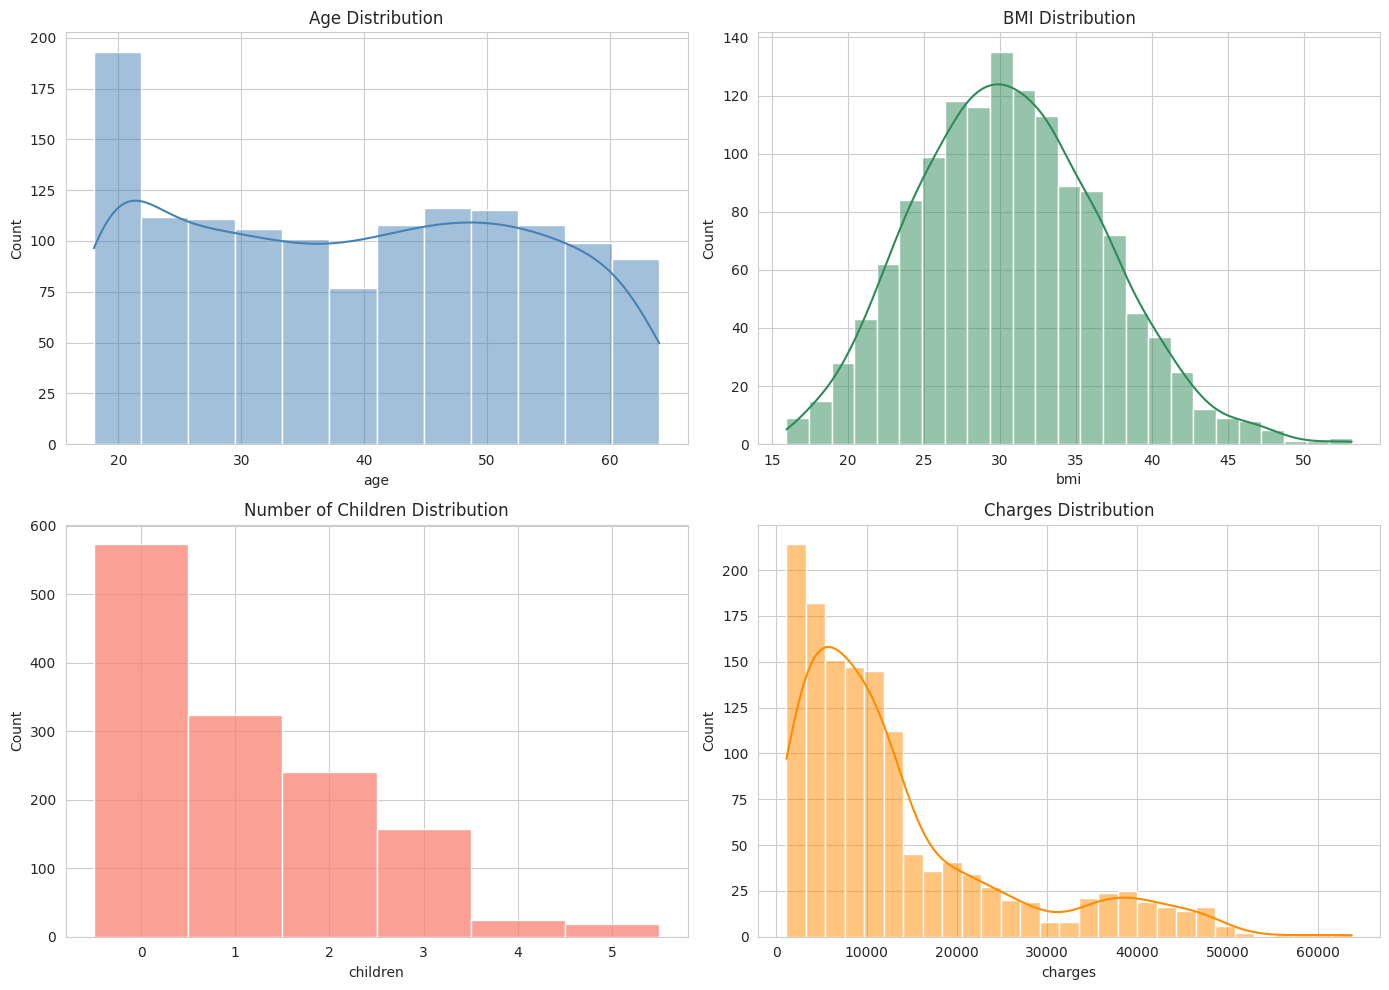

In [52]:
fig,axes=plt.subplots(2,2,figsize=(14,10))
sns.histplot(df["age"],kde=True,ax=axes[0,0],color="steelblue")
axes[0,0].set_title("Age Distribution")
sns.histplot(df["bmi"],kde=True,ax=axes[0,1],color="seagreen")
axes[0,1].set_title("BMI Distribution")
sns.histplot(df["children"],discrete=True,ax=axes[1,0],color="salmon")
axes[1,0].set_title("Number of Children Distribution")
sns.histplot(df["charges"],kde=True,ax=axes[1,1],color="darkorange")
axes[1,1].set_title("Charges Distribution")
plt.tight_layout()
plt.show()

In [55]:
for col in ["bmi", "charges"]:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  n_out = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
  print(f"{col}: {n_out} outliers")


bmi: 9 outliers
charges: 139 outliers


In [57]:
df.groupby("smoker")["charges"].agg(["mean","median","std","count"])

,mean,median,std,count
smoker,,,,
no,8440.660307,7345.72660,5992.973800,1063
yes,32050.231832,34456.34845,11541.547176,274


In [58]:
def bmi_category(bmi):
  if bmi < 18.5:
    return "Underweight"
  elif 18.5 <= bmi < 24.9:
    return "Normal Weight"
  elif 25 <= bmi < 30:
    return "Overweight"
  else:
    return "Obese"

In [59]:
df["bmi_category"]=df["bmi"].apply(bmi_category)

In [60]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Obese
2,28,male,33.000,3,no,southeast,4449.46200,Obese
3,33,male,22.705,0,no,northwest,21984.47061,Normal Weight
4,32,male,28.880,0,no,northwest,3866.85520,Overweight


In [61]:
df["bmi_category"].value_counts()

,count
bmi_category,
Obese,709
Overweight,386
Normal Weight,222
Underweight,20


In [62]:
df.groupby("bmi_category")["charges"].mean().sort_values().round(2)

,charges
bmi_category,
Underweight,8852.20
Normal Weight,10379.50
Overweight,10987.51
Obese,15559.54


In [64]:
df["log_charges"]=np.log1p(df["charges"])

In [65]:
df["charges"].skew()

np.float64(1.5153909108403483)

In [66]:
df["log_charges"].skew()

np.float64(-0.08955835073325998)

In [67]:
df_model=pd.get_dummies(
    df,
    columns=["sex","smoker","region"],
    drop_first=True
)
print(df_model.columns.to_list())

['age', 'bmi', 'children', 'charges', 'bmi_category', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [68]:
df_model.head()

,age,bmi,children,charges,bmi_category,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,Overweight,9.734236,False,True,False,False,True
1,18,33.770,1,1725.55230,Obese,7.453882,True,False,False,True,False
2,28,33.000,3,4449.46200,Obese,8.400763,True,False,False,True,False
3,33,22.705,0,21984.47061,Normal Weight,9.998137,True,False,True,False,False
4,32,28.880,0,3866.85520,Overweight,8.260455,True,False,True,False,False


In [70]:
feature_cols = [c for c in df_model.columns if c not in ["charges", "log_charges", "bmi_category"]]
x = df_model[feature_cols]
y = df_model["log_charges"]

In [72]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print(f"Training set shape: {x_train.shape}")
print(f"Testing set shape: {x_test.shape}")

Training set shape: (1069, 8)
Testing set shape: (268, 8)


In [77]:
y_test_real=np.expm1(y_test)
cadidate_models={
    "LinearRegression":LinearRegression(),
    "RandomForestRegressor":RandomForestRegressor(n_estimators=300,max_depth=6,n_jobs=-1),
    "GradientBoostingRegressor":HistGradientBoostingRegressor(max_iter=300,max_depth=3,learning_rate=0.05)}
train_models={}
metrics_rows=[]
for name,model in cadidate_models.items():
    model.fit(x_train,y_train)
    y_pred_log=model.predict(x_test)
    y_pred=np.expm1(y_pred_log)
    r2=r2_score(y_test_real,y_pred)
    mae=mean_absolute_error(y_test_real,y_pred)
    mse=mean_squared_error(y_test_real,y_pred)
    rmse=np.sqrt(mse)

    train_models[name]=model
    metrics_rows.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2_Score": round(r2, 4)
    })

pd.DataFrame(metrics_rows)

,Model,MAE,RMSE,R2_Score
0,LinearRegression,3755.92,7197.03,0.7181
1,RandomForestRegressor,2014.07,4244.16,0.9020
2,GradientBoostingRegressor,2372.37,4621.48,0.8838


In [79]:
results = pd.DataFrame(metrics_rows).sort_values("R2_Score", ascending=False).reset_index(drop=True)
results

,Model,MAE,RMSE,R2_Score
0,RandomForestRegressor,2014.07,4244.16,0.9020
1,GradientBoostingRegressor,2372.37,4621.48,0.8838
2,LinearRegression,3755.92,7197.03,0.7181


In [81]:
best_model_name = results.loc[0, "Model"]
Best_model = train_models[best_model_name]

In [82]:
best_model_name

'RandomForestRegressor'

In [84]:
Best_model

RandomForestRegressor(max_depth=6, n_estimators=300, n_jobs=-1)

In [87]:
joblib.dump(Best_model, "insurence_model.pkl")
joblib.dump(feature_cols, "model_features.pkl")
joblib.dump(df_model, "model_df.pkl")

['model_df.pkl']

In [89]:
from google.colab import files

# Download the model file
files.download('insurence_model.pkl')

# Download the features configuration file
files.download('model_features.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>